<a href="https://colab.research.google.com/github/rozmar/Analyzing-Open-Neuroscience-Data-SZTE-2027/blob/main/Modul%201/Orai_gyakorlo_07_megoldas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7. Órai gyakorló feladat - Megoldás

Az alábbi gyakorló feladatban egy képzeletbeli kísérlet eredményeit fogod vizsgálni.
 - *A kísérlet kitalált, az adatok mesterségesen generáltak.*

A kísérlethez tartozik egy rögzített jel. Ez 10 másodperc hosszú, a mintavételezése 1 kHz (azaz két pont között 1 ms eltérés van).

A kísérlet során kétfajta stimulust alkalmaztak, ezeket `A` és `B` névvel jelöltük. Ezek a stimulusok különböző időpontokban jelentek meg, amiket egy fájlban találsz meg.

A `signal.csv` fájlban két oszlopot találsz:
 - `time`: ez tárolja az egyes adatpontok időtartamát, ms-ben kifejezett egész számként megadva
 - `v`: az egyes adatpontokban mért feszültségérték

A fájl az alábbi linken érhető el:
[https://inf.u-szeged.hu/~borde/gy07/signal.csv](https://inf.u-szeged.hu/~borde/gy07/signal.csv)

A `stimulus.csv` fájlban két oszlopot találsz:
 - `time`: egy adott stimulus időpontja (ms-ban megadva)
 - `label`: a stimulus fajtája, lehetséges értékei `A` és `B` betű

A fájl az alábbi linken érhető el:
[https://inf.u-szeged.hu/~borde/gy07/stimulus.csv](https://inf.u-szeged.hu/~borde/gy07/stimulus.csv)

A következő feladatok során ezekkel az adatokkal kell dolgoznod.

## 1. feladat

Olvasd be a `signal.csv` fájlban található jelet és a `stimulus.csv` fájlban található stimulusokat egy-egy `DataFrame`-be. Vágj ki 300 ms hosszú (301 pontból álló) szakaszokat az egyes stimulusok körül az alábbiak szerint:
 - a kivágás a stimulus előtt kezdődjön 100 ms-mal kezdődjön, és a stimulus után 200 ms-mal később érjen véget
 - a teljes intervallum 300 ms, de a kivágásban szerepeljen az első és utolsó pont is, ezért lesz összesen 301 elemű a kivágott array

Ezután generálj egy közös idővektort a kivágott szakaszoknak
 - -100 ms-tól 200 ms-ig tartson
 - 1 ms legyen a lépésköz (tehát összesen 301 elemű lesz a vektor)

Az idővektorból és a kivágott szakaszokból készíts egy `DataFrame`-et:
 - első oszlop neve legyen `time`, amibe az idővektort teszed
 - a második oszloptól kezdve legyenek az egyes kivágott szakaszok `v1`, `v2` stb névvel

In [4]:
import pandas as pd
import numpy as np

In [21]:
# adatok betöltése
signal = pd.read_csv('https://inf.u-szeged.hu/~borde/gy07/signal.csv')
stimulus = pd.read_csv('https://inf.u-szeged.hu/~borde/gy07/stimulus.csv')

In [22]:
# szakaszok kivágása
segments = []
for stim_t in stimulus.loc[:, 'time']: # vegyük sorra a stimulus időket
  cut_start = stim_t - 100 # menjünk tőle előre 100-at
  cut_end = stim_t + 200 # menjünk utána 200-at
  # mely időpontok esnek ebbe az intervallumba (a végeket is beleértve)?
  mask = (cut_start <= signal.loc[:, 'time']) & (signal.loc[:, 'time'] <= cut_end)
  # tároljuk le az ehhez tartozó 'v' oszlop értékeit
  segments.append(signal.loc[mask, 'v'].values)

In [23]:
# generáljunk egy vektort
t = np.arange(-100, 201)

In [24]:
# tároljuk el az időtengelyt
data = {'time': t}
# vegyük sorra a kivágott szakaszokat
for i, segment in enumerate(segments):
  # tegyük be megfelelő névvel a dict-be
  data['v' + str(i+1)] = segments[i]
# a dict-ből csináljunk DataFrame-et
segments = pd.DataFrame(data)


## 2. feladat
Az előző feladat során elkészített `DataFrame`-mel kell dolgoznod.
 - *Ha nem sikerült, akkor a [https://inf.u-szeged.hu/~borde/gy07/segments.csv](https://inf.u-szeged.hu/~borde/gy07/segments.csv) címen található *CSV* fájlból betöltheted.*

### 2.a
Számítsd ki a kivágott szakaszok stimulusonkénti átlagát. Tehát vedd azokat a szakaszokat, amik azonos címkéjű stimulushoz tartoztak, majd számítsd ki ezeknek az átlagát, így kapsz két 301 méretű **numpy** arrayt. Ábrázold az átlag szakaszokat:
 - három ábrapanel legyen egymás mellett
 - az első és harmadik panelen legyen az `'A'` és `'B'` címkével ellátott stimulusok átlaga. Az `'A'` piros, a `'B'` zöld színnel jelenítsd meg.
 - a középső (második) panelen egy panelre kerüljön a két átlag jel, az előbbi színekkel kirajzolva.
 - Adj címet az egyes paneleknek. A két szélső címe legyen `'Stimulus A'` és `'Stimulus B'`, a középső pedig `'Combined plot'`.
 - Feliratozd a tengelyeket. Az *x* tengely címe legyen `'Time (ms)'`, az *y* tengely címe pedig `'Voltage (mV)'`.
 - Mindhárom panel x tartománya legyen `(-100, 200)`, az y tartománya pedig `(0, 2)`.
 - *Szorgalmi: A középső panelhez adj egy jelmagyarázatot, ami jelzi, melyik színű vonal mit jelent.*

![l07ex02.png](https://inf.u-szeged.hu/~borde/gy07/l07ex02.png)


In [16]:
import matplotlib.pyplot as plt

In [25]:
# beállítjuk a time oszlopot indexnek, így könnyebb kezelni a többi oszlopot
segments = segments.set_index('time')

In [31]:
# a részeredményeket egy dict-be rakom
stim_means = {}
for label in ['A', 'B']: # vegyük sorra a lehetséges címkéket
  stim_mask = stimulus.loc[:, 'label'] == label # válasszuk ki az adott stimulusokat
  # válasszuk ki az ehhez tartozó szakaszokat
  # a mask esetén kell a values, hogy csak az értékeket kérje le, mert egyébként ütköznek az indexek
  stim_segments = segments.loc[:, stim_mask.values]
  # átlagoljuk, DataFrame-ként, így megmarad a time index
  stim_means[label] = stim_segments.mean(axis=1)

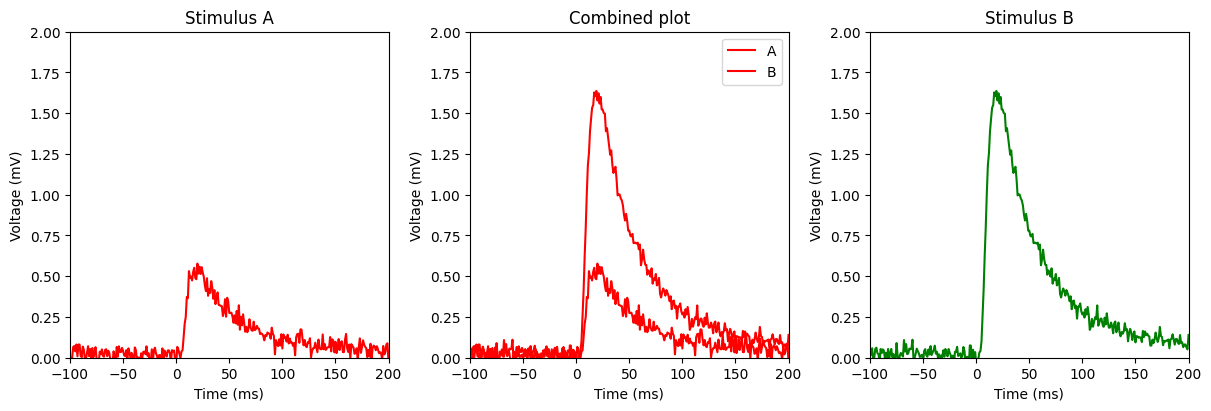

In [38]:
# létrehozzuk a paneleket
# layout='constrained' - ha esetleg zsúfolt lenne az ábra, ez széthúzza úgy, hogy ne legyen átfedés
fig, axs = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')

# kirajzolom az első szakaszt az első panelre
axs[0].plot(stim_means['A'].index, stim_means['A'].values, color='red')
# kirajzolom a második szakaszt a második panelre
axs[2].plot(stim_means['B'].index, stim_means['B'].values, color='green')

# kirajzolom a két jelet a középső panelre
for label in ['A', 'B']:
  # ha megadok label paramétert, akkor tudok jelmagyarázatot hozzáadni a legend() függvénnyel
  axs[1].plot(stim_means[label].index, stim_means[label].values, color='red', label=label)

# Ha a plot-nál adtunk meg label paramétert, akkor így jeleníthetjük meg a jelmagyarázatot
axs[1].legend()

ax_titles = ['Stimulus A', 'Combined plot', 'Stimulus B']
# beállítom a panelek tulajdonságait
for i in range(3):
  axs[i].set_xlim(-100, 200)
  axs[i].set_ylim(0, 2)
  axs[i].set_xlabel('Time (ms)')
  axs[i].set_ylabel('Voltage (mV)')
  axs[i].set_title(ax_titles[i])

plt.show()

### 2.b
A kivágott szakaszaidat oszd fel három 100 ms hosszúságú részre: `[-100, 0)`, `[0, 100)`, `[100, 200)`. Az egyes intervallumaid balról zártak, jobbról nyitottak, azaz az adott szakaszba az eleje beletartozik, a vége már nem. Mivel a három intervallumod egyenlő hosszúságú, így az utolsó adatpont kimarad, ettól most eltekintünk.

Számítsd ki mindegyik szakaszra mind a három részre az átlagos értéket. Ezeknek az eredményét tárold el egy új `DataFrame`-be:
 - minden sor egy szakaszhoz tartozzon
 - az első három oszlop a három intervallum átlag értéke, nevük legyen `i1`, `i2` és `i3`
 - negyedik oszlopként szúrd be a `stimulus.csv` fájlból a megfelelő stimulus címkéjét, az oszlop neve legyen `label`

In [40]:
# eltárolom a három intervallumot, hogy ciklussal is használhassam
intervals = [(-100, 0), (0, 100), (100, 200)]
# ide gyűjtöm majd az egyes sorokat
means = []
# annyiszor kell végigmennem, ahány oszlop van a segments DataFrame-ben
for i in range(segments.shape[1]):
  # lekérem a szakasz v értékeit
  segment_v = segments.iloc[:, i].values
  # ide gyűjtöm majd az egyes részintervallum átlagokat
  row_mean = {}
  # sorra veszem az intervallumokat
  for ii, interval in enumerate(intervals):
    # megnézem, mely időpontok esnek az adott intervallumba - a második esetben csak <, nem <=
    mask = (interval[0] <= segments.index) & (segments.index < interval[1])
    # eltárolom az adott intervallum átlagát
    row_mean['i' + str(ii + 1)] = np.mean(segment_v[mask])
  # hozzáadom a stimulus címkéjét
  row_mean['label'] = stimulus.iloc[i]['label']
  # eltárolom a listába
  means.append(row_mean)
# megcsinálom a DataFrame-et a dict-ek listájából
interval_means = pd.DataFrame(means)


## 3. feladat
Ebben a feladatban az előző feladatban elkészített átlag értékekkel kell tovább dolgozni.

### 3.a
Készíts statisztikát stimulus típusa szerint csoportosítva a kivágott szakaszok három harmadáról:
 - Mennyi volt az átlag és a szórás érték az első, második és harmadik harmadban? Hány stimulus volt az egyes típusokból?

Ábrázold egy-egy oszlopdiagramon a két különböző stimulus átlagait az egyes szakaszokban. Tehát készíts egy ábrát, amin két panel van. Az első panelen az `'A'`, második panelen a `'B'` stimulus értékei szerepeljenek, mindkét panelen három oszlop legyen. Az oszlopok alatti feliratok legyenek az intervallumok:
 - `[-100, 0)`, `[0, 100)` és `[100, 200)`
 - Az oszlopok legyenek a stimulus alapján színezve (`'A'` piros, `'B'` zöld)
 - Mindkét panelnek legyen az y tengely tartománya `(0, 1)`.
 - A panelek címe legyen `Stimulus A (x)` és `Stimulus B (y)`, ahol x és y helyére írd be az egyes stimulusok elemszámát

*Szorgalmi: Az egyes oszlopokon jelenítsd meg fekete vonalakkal a szórást is.*

![l07ex03a.png](https://inf.u-szeged.hu/~borde/gy07/l07ex03a.png)

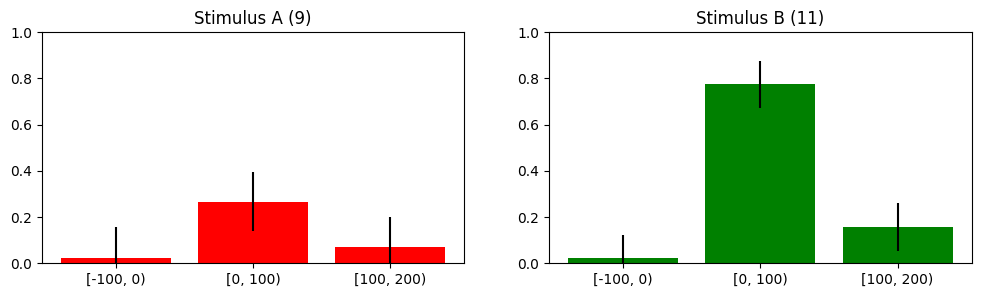

In [55]:
# elkészítjük a statisztikákat
#  mivel a darabszám minden oszlopban annyi, ezért itt kiválasztjuk az i1-et
cnts = interval_means.groupby(by='label')['i1'].count()
#  átlagot és szórást számolunk - lehetne egyben, de akkor hierarchikus oszlopnevek jönnek létre
means = interval_means.groupby(by='label').mean()
stds = interval_means.groupby(by='label').std()

# elkészítjük a paneleket
fig, axs = plt.subplots(1, 2, figsize=(12, 3))
# zip-pel összecsomagoljuk a stimulushoz szükséges infókat: címke, szín és tengely
for label, color, ax in zip(['A', 'B'], ['red', 'green'], axs):
  # kirajzoljuk az oszlopokat
  ax.bar([0, 1, 2], means.loc[label, :], color=color)
  # vlines függvénnyel adott x pontokban, adott y1 és y2 értékek között húzhatunk függőleges vonalakat
  ax.vlines(
      [0, 1, 2],
      means.loc[label, :] - stds.loc[label, :],
      means.loc[label, :] + stds.loc[label, :],
      color='black'
  )
  # beállítjuk a panel jellemzőit
  ax.set_ylim(0, 1)
  ax.set_xticks([0, 1, 2], labels=['[-100, 0)', '[0, 100)', '[100, 200)'])
  ax.set_title('Stimulus ' + label + ' (' + str(cnts[label]) + ')')
plt.show()

### 3.b
Számítsd ki, hogy az egyes stimulus típusok esetén mekkorát változott a stimulus hatására az érték a stimulus előttihez képest (azaz mi a `[0, 100)` és a `[-100, 0)` intervallumok átlagának a különbsége).

Készíts ezekből az értékekből egy "strip plotot". Ezt úgy tudod megtenni, hogy készítesz egy pontdiagramot úgy, hogy a pontok y értékei a kiszámolt különbségek, az x értékei pedig a következőképpen tudod kiszámolni:
 - Veszed az 1 vagy 2 számot annak függvényében, hogy `'A'` vagy a `'B'` stimulushoz tartozott az érték
 - Hozzáadsz egy egyenletes eloszlásból származó véletlen számot

A két stimulus pontjainak színe legyen piros és zöld, ahogy eddig. A két ponthalmaz "közepéhez" (azaz 1 és 2 pozícióba) írd a stimulus nevét. Az y tengely tartománya legyen `(0, 1)`.

![l07ex03b.png](https://inf.u-szeged.hu/~borde/gy07/l07ex03b.png)

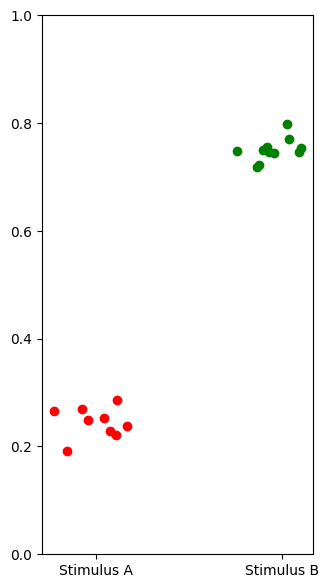

In [63]:
# kiszámoljuk a különbséget szakaszonként
difference = interval_means.loc[:, 'i2'] - interval_means.loc[:, 'i1']
# készítünk egy ábrapanelt
fig, ax = plt.subplots(figsize=(3.5, 7))
# használható együtt a zip és az enumerate is:
#  - a zip összecsomagolja betűjelet a színnel
#  - az enumerate ezekhez indexet rendel 0-tól kezdődően
for i, (label, color) in enumerate(zip(['A', 'B'], ['red', 'green'])):
  # kiválasztjuk az adott stimulushoz tartozó különbségeket
  label_diffs = difference.loc[interval_means.loc[:, 'label'] == label]
  # generálunk hozzá egy véletlen szórást a sorszáma (i) körül
  x = np.random.uniform(-0.25, 0.25, size=label_diffs.shape) + i
  # kirajzoljuk a pontokat a megadott színnel
  ax.scatter(x, label_diffs, color=color)
ax.set_ylim(0, 1)
ax.set_xticks([0, 1], labels=['Stimulus A', 'Stimulus B'])
plt.show()